# Coffee production over a week

Plan production from fresh coffee cherries through drying, hulling, roasting, grinding, and brewing. The model minimizes purchasing and production costs while meeting daily demand. Roasting also yields whole beans and silverskin, and brewing leaves spent grounds. The input tables are included below.

## Inputs

Each process row gives tonnes of material or units of electricity per unit of activity. Negative coefficients are inputs. Each process has a capacity limit of 100,000 activity units per day, a capacity cost of 110, and an operating cost of 1 per activity unit.

In [1]:
from math import isclose

import pandas as pd
from energia import Model, Periods, Process, Resource
from energia.modeling.parameters.conversion import Conversion
from gana import inf

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
demand = [7000, 6300, 6300, 7000, 4200, 2800, 2800]

# Resource: maximum purchase, purchase price, upstream emissions.
purchases = {
    "cherries": (100_000, 1, 50),
    "water": (1_000_000, 0.01, 40),
    "power": (1_000_000, 1, 40),
}
production = {
    "drying": ({"cherries": -1, "dried_cherries": 0.8, "power": -2}, 20_000),
    "hulling": (
        {"dried_cherries": -1, "husk": 0.25, "green_beans": 0.75, "power": -1.5},
        30_000,
    ),
    "roasting": (
        {"green_beans": -1, "whole_beans": 0.66, "silverskin": 0.1,
         "roasted_coffee": 0.24, "power": -3},
        40_000,
    ),
    "grinding": ({"roasted_coffee": -1, "grounds": 1, "power": -1}, 300_000),
    "brewing": (
        {"grounds": -1, "spent_grounds": 1, "brewed_coffee": 5, "water": -5, "power": -1.5},
        60_000,
    ),
}
byproducts = ["husk", "whole_beans", "silverskin", "spent_grounds"]

## Model and solve

Capacity is sized for the week. The conversions and demand bounds are applied for each day. The emissions account covers purchases and operating activity.

In [2]:
m = Model("coffee")
m.day = Periods()
m.week = len(days) * m.day
resources = dict.fromkeys(name for balance, _ in production.values() for name in balance)
m.declare(Resource, list(resources))

cost = 0
emissions_terms = []
for name, (limit, price, factor) in purchases.items():
    purchase = getattr(m, name).consume(m.day)
    _ = purchase <= limit
    cost += price * sum(purchase.V())
    emissions_terms.append((factor, purchase))

for name in byproducts:
    _ = getattr(m, name).release(m.day) >= 0
served = m.brewed_coffee.release(m.day)
_ = served >= demand

for name, (balance, factor) in production.items():
    coefficients = {getattr(m, resource): value for resource, value in balance.items()}
    process = Process(Conversion.from_balance(coefficients, basis=next(iter(coefficients))))
    setattr(m, name, process)
    _ = process.capacity(m.week) <= 100_000
    dispatch = process.operate(m.day)
    _ = dispatch <= 1
    process.locate()
    cost += 110 * process.capacity(m.week).V()[0] + sum(dispatch.V())
    emissions_terms.append((factor, dispatch))

m.program.cost = inf(cost)
m.opt()

## Weekly schedule

The conversion chain yields 0.72 tonnes of brewed coffee per tonne of fresh cherries. The resource balance provides an independent check on the solution.

In [3]:
cherries = m.cherries.consume(m.day).output(aslist=True)
coffee = served.output(aslist=True)
assert all(isclose(actual, required) for actual, required in zip(coffee, demand, strict=True))
assert isclose(sum(cherries) * 0.72, sum(demand))
print(f"Weekly cost: {m.program.active_objective.X:,.2f}")
footprint = sum(factor * sum(flow.output(aslist=True)) for factor, flow in emissions_terms)
print(f"Weekly emissions: {footprint:,.0f}")

pd.DataFrame({"Demand": demand, "Brewed coffee": coffee, "Fresh cherries": cherries}, index=days)

,Demand,Brewed coffee,Fresh cherries
Mon,7000,7000.0,9722.222222
Tue,6300,6300.0,8750.000000
Wed,6300,6300.0,8750.000000
Thu,7000,7000.0,9722.222222
Fri,4200,4200.0,5833.333333
Sat,2800,2800.0,3888.888889
Sun,2800,2800.0,3888.888889


## Daily material yield

Compare fresh-cherry purchases with brewed-coffee delivery on the same
daily coordinates. The conversion chain determines the difference between
these quantities; both retain the example's material basis.

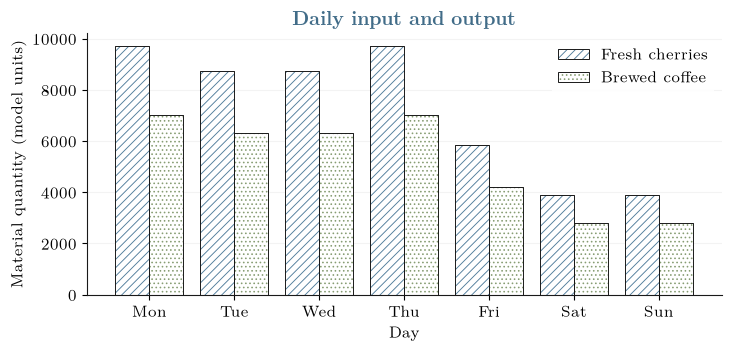

In [4]:
cherries_plot = m.cherries.consume(m.day).bar(label="Fresh cherries")
coffee_plot = served.bar(label="Brewed coffee")
yield_plot = (cherries_plot + coffee_plot).with_options(
    title="Daily input and output",
    xlabel="Day",
    ylabel="Material quantity (model units)",
    ticks=list(range(len(days))),
    tick_labels=days,
    ylim=(0, None),
)
yield_plot.show(fig_size=(7.2, 3.4));